In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

np.random.seed(42)


In [15]:
r = r'C:\DGA-Transformers'
os.chdir(r)

# ----------------------------------------
# Load dataset
# ----------------------------------------
dga = pd.read_csv('dga-dataset.txt', sep=',', header=None)
dga.columns = ['label', 'origin', 'domain']

# Handle string or numeric labels
if dga['label'].dtype == object:
    dga['label'] = dga['label'].str.lower().map({
        'benign': 0, 'legit': 0, 'normal': 0,
        'dga': 1, 'malicious': 1
    })
    dga = dga.dropna(subset=['label'])
    labels = dga['label'].astype(int).values
else:
    labels = dga['label'].astype(int).values

domains = dga['domain'].astype(str).tolist()

In [16]:
allowed_chars = "abcdefghijklmnopqrstuvwxyz0123456789-"
char2idx = {c: i+1 for i, c in enumerate(allowed_chars)}
tlds = ['com', 'net', 'org', 'info', 'biz', 'io', 'gov']

def preprocess_domain(domain):
    domain = domain.lower()
    tld_feat = 0
    for i, tld in enumerate(tlds, 1):
        if domain.endswith('.' + tld):
            tld_feat = i
            domain = domain[:-(len(tld)+1)]
            break
    domain = ''.join([c for c in domain if c in allowed_chars])
    return domain, tld_feat

MAX_LEN = 50
SEQ_LEN = MAX_LEN + 1

def encode_domain(domain, max_len=MAX_LEN):
    domain, tld_feat = preprocess_domain(domain)
    vec = [char2idx.get(c, 0) for c in domain[:max_len]]
    if len(vec) < max_len:
        vec += [0] * (max_len - len(vec))
    vec.append(tld_feat)
    return np.array(vec, dtype=np.int32)

X = np.array([encode_domain(d) for d in domains], dtype=np.int32)
y = np.array(labels, dtype=np.int32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ----------------------------------------
# Utility functions
# ----------------------------------------
def softmax(x):
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / e_x.sum(axis=-1, keepdims=True)

def layer_norm(x, eps=1e-6):
    mean = x.mean(axis=-1, keepdims=True)
    std = x.std(axis=-1, keepdims=True)
    return (x - mean) / (std + eps)

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

In [17]:
class SelfAttention:
    def __init__(self, d_model):
        self.d_model = d_model
        self.Wq = np.random.randn(d_model, d_model) * 0.1
        self.Wk = np.random.randn(d_model, d_model) * 0.1
        self.Wv = np.random.randn(d_model, d_model) * 0.1
        self.scale = np.sqrt(d_model)

    def forward(self, x):
        Q = x @ self.Wq
        K = x @ self.Wk
        V = x @ self.Wv

        batch_size, seq_len, d_model = x.shape
        out = np.zeros_like(x)

        for i in range(batch_size):
            scores = (Q[i] @ K[i].T) / self.scale
            attn = softmax(scores)
            out[i] = attn @ V[i]

        return out


class TransformerBlock:
    def __init__(self, d_model, d_ff):
        self.attn = SelfAttention(d_model)
        self.W1 = np.random.randn(d_model, d_ff) * 0.1
        self.W2 = np.random.randn(d_ff, d_model) * 0.1

    def forward(self, x):
        attn_out = self.attn.forward(x)
        x = layer_norm(x + attn_out)

        ff = np.maximum(0, x @ self.W1) @ self.W2
        x = layer_norm(x + ff)

        return x


class ImprovedTransformer:
    def __init__(self, vocab_size=len(char2idx)+1, max_len=SEQ_LEN,
                 d_model=96, d_ff=192, num_blocks=2):

        self.vocab_size = vocab_size
        self.max_len = max_len
        self.d_model = d_model

        self.embedding = np.random.randn(vocab_size, d_model).astype(np.float32) * 0.1
        self.pos_encoding = np.random.randn(max_len, d_model).astype(np.float32) * 0.1

        self.blocks = [TransformerBlock(d_model, d_ff) for _ in range(num_blocks)]
        self.Wo = np.random.randn(d_model, 1).astype(np.float32) * 0.1

    def forward_features(self, X_batch):
        emb = self.embedding[X_batch]
        emb = emb + self.pos_encoding[:X_batch.shape[1]]

        for block in self.blocks:
            emb = block.forward(emb)

        return emb.mean(axis=1)

    def forward(self, X_batch):
        z = self.forward_features(X_batch)
        logits = z @ self.Wo
        return sigmoid(logits)

    def predict_batch(self, X, batch_size=128):
        n = len(X)
        out = np.zeros(n)
        for start in range(0, n, batch_size):
            end = min(start+batch_size, n)
            out[start:end] = self.forward(X[start:end]).flatten()
        return out

    def train(self, X, y, epochs=25, lr=0.01, batch_size=256, verbose=1):
        n = len(X)

        for epoch in range(epochs):
            idx = np.arange(n)
            np.random.shuffle(idx)

            total_loss = 0
            total = 0
            correct = 0

            for start in range(0, n, batch_size):
                end = min(start + batch_size, n)
                batch_idx = idx[start:end]

                Xb = X[batch_idx]
                yb = y[batch_idx].astype(np.float32)

                z = self.forward_features(Xb)
                logits = z @ self.Wo
                preds = sigmoid(logits).flatten()

                preds = np.clip(preds, 1e-8, 1-1e-8)

                loss = -np.mean(yb*np.log(preds) + (1-yb)*np.log(1-preds))

                grad = (preds - yb).reshape(-1, 1)
                grad_Wo = (z.T @ grad) / len(Xb)

                self.Wo -= lr * grad_Wo

                total_loss += loss * len(Xb)
                total += len(Xb)
                correct += np.sum((preds > 0.5).astype(int) == yb)

            if verbose:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/total:.4f} - Acc: {correct/total:.4f}")

In [19]:
# Train model
# ----------------------------------------
print("Training Transformer...")
model = ImprovedTransformer()
model.train(X_train, y_train, epochs=10, batch_size=128, lr=0.01, verbose=1)

Training Transformer...
Epoch 1/10 - Loss: 0.6080 - Acc: 0.7013
Epoch 2/10 - Loss: 0.5521 - Acc: 0.7395
Epoch 3/10 - Loss: 0.5286 - Acc: 0.7512
Epoch 4/10 - Loss: 0.5141 - Acc: 0.7585
Epoch 5/10 - Loss: 0.5039 - Acc: 0.7638
Epoch 6/10 - Loss: 0.4960 - Acc: 0.7679
Epoch 7/10 - Loss: 0.4896 - Acc: 0.7709
Epoch 8/10 - Loss: 0.4844 - Acc: 0.7736
Epoch 9/10 - Loss: 0.4800 - Acc: 0.7757
Epoch 10/10 - Loss: 0.4761 - Acc: 0.7780



=== TEST RESULTS ===
Accuracy : 0.7814935546006816
Precision: 0.8267815380382446
Recall   : 0.7122814814814815
F1-score : 0.7652723394772865
ROC-AUC  : 0.8557152260203298
Confusion Matrix:
[[57407 10073]
 [19421 48079]]


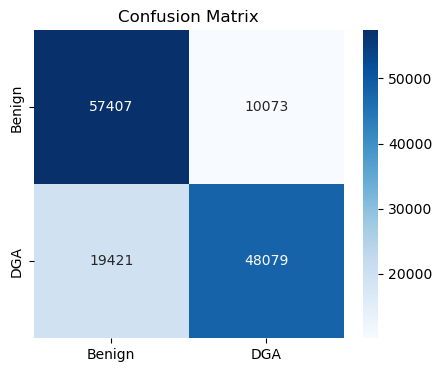

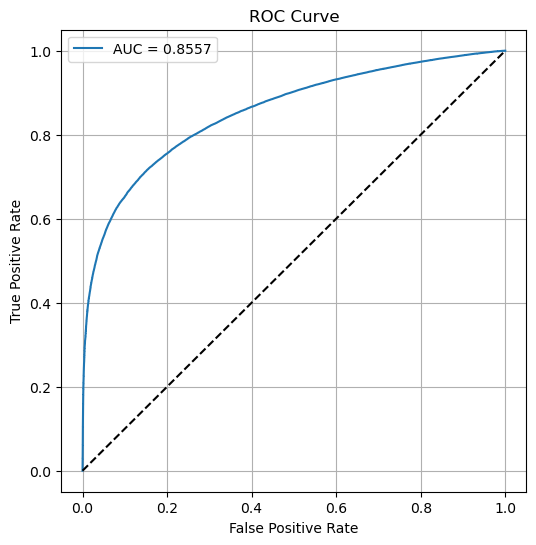

In [20]:
# Evaluation
# ----------------------------------------
y_prob = model.predict_batch(X_test)
y_pred = (y_prob > 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
rocauc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print("\n=== TEST RESULTS ===")
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("ROC-AUC  :", rocauc)
print("Confusion Matrix:")
print(cm)

# ----------------------------------------
# Confusion Matrix Plot
# ----------------------------------------
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'DGA'],
            yticklabels=['Benign', 'DGA'])
plt.title("Confusion Matrix")
plt.show()

# ----------------------------------------
# ROC Curve
# ----------------------------------------
fpr, tpr, th = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"AUC = {rocauc:.4f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()